# Task 39: Dropout and Batch Normalization From Scratch

Implement a small MLP, inverted dropout, batch statistics, running moments, and batch-normalization gradients directly with NumPy.

Unique records: 302
                      accuracy  precision  recall     f1
Plain MLP                0.918      0.912   0.939  0.925
Dropout + batch norm     0.852      0.800   0.970  0.877


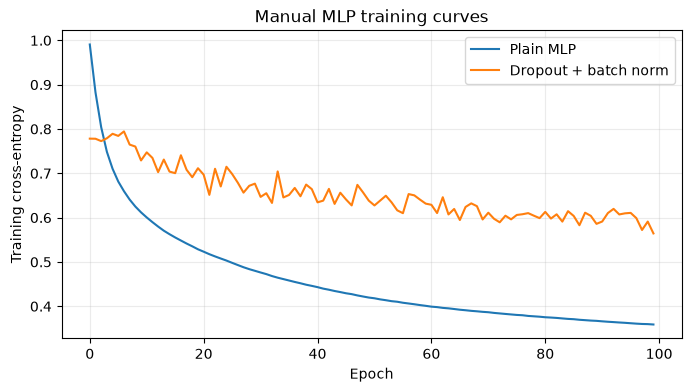

Batch norm running variances: [[1.896, 3.362, 1.065, 1.683, 1.337, 1.72, 1.419, 2.051, 1.364, 2.587, 1.288, 3.055, 1.375, 2.014, 4.456, 3.073], [1.613, 2.017, 1.684, 1.943, 0.871, 1.43, 0.537, 0.554]]
Mean mini-batch variance observed: 1.6543


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

csv_options = [Path('heart.csv'), Path('Task_39_Dropout_Batch_Normalization_From_Scratch/heart.csv'), Path('Heart_Disease_Tasks/Task_39_Dropout_Batch_Normalization_From_Scratch/heart.csv')]
data = pd.read_csv(next(path for path in csv_options if path.is_file())).drop_duplicates().reset_index(drop=True)
feature_names = [name for name in ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal'] if name in data]
X, y = data[feature_names].to_numpy(float), data['target'].to_numpy(int)
rng = np.random.default_rng(39)
train_idx, test_idx = [], []
for label in np.unique(y):
    indices = np.flatnonzero(y == label); rng.shuffle(indices)
    split = int(round(0.8 * len(indices))); train_idx.extend(indices[:split]); test_idx.extend(indices[split:])
train_idx, test_idx = np.array(train_idx), np.array(test_idx)
rng.shuffle(train_idx); rng.shuffle(test_idx)
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
mean, scale = X_train.mean(axis=0), X_train.std(axis=0); scale[scale == 0] = 1.0
X_train, X_test = (X_train - mean) / scale, (X_test - mean) / scale


class ManualMLP:
    def __init__(self, hidden=(16, 8), dropout=0.0, use_batch_norm=False, seed=39):
        self.hidden, self.dropout, self.use_batch_norm, self.seed = hidden, dropout, use_batch_norm, seed

    def fit(self, x, labels, epochs=100, batch_size=32, learning_rate=0.01):
        rng = np.random.default_rng(self.seed)
        sizes = (x.shape[1], *self.hidden, 1)
        self.weights = [rng.normal(0, np.sqrt(2 / sizes[i]), (sizes[i], sizes[i + 1])) for i in range(len(sizes) - 1)]
        self.biases = [np.zeros((1, sizes[i + 1])) for i in range(len(sizes) - 1)]
        hidden_count = len(self.hidden)
        self.gamma = [np.ones((1, width)) for width in self.hidden]
        self.beta = [np.zeros((1, width)) for width in self.hidden]
        self.running_mean = [np.zeros((1, width)) for width in self.hidden]
        self.running_var = [np.ones((1, width)) for width in self.hidden]
        self.loss_history, self.variance_history = [], []
        labels = labels.reshape(-1, 1).astype(float)
        for _ in range(epochs):
            order = rng.permutation(len(x)); total_loss = 0.0
            for start in range(0, len(x), batch_size):
                indices = order[start:start + batch_size]; xb, yb = x[indices], labels[indices]
                activations, caches = [xb], []
                for layer in range(hidden_count):
                    z = activations[-1] @ self.weights[layer] + self.biases[layer]
                    if self.use_batch_norm:
                        mu, var = z.mean(axis=0, keepdims=True), z.var(axis=0, keepdims=True)
                        inv = 1 / np.sqrt(var + 1e-5); norm = (z - mu) * inv
                        scaled = self.gamma[layer] * norm + self.beta[layer]
                        self.running_mean[layer] = 0.9 * self.running_mean[layer] + 0.1 * mu
                        self.running_var[layer] = 0.9 * self.running_var[layer] + 0.1 * var
                        self.variance_history.append(float(var.mean()))
                    else:
                        norm, inv, scaled = z, None, z
                    activated = np.maximum(scaled, 0)
                    mask = None
                    if self.dropout and len(indices) > 1:
                        mask = (rng.random(activated.shape) >= self.dropout).astype(float) / (1 - self.dropout)
                        activated *= mask
                    caches.append((norm, inv, scaled, mask)); activations.append(activated)
                logits = activations[-1] @ self.weights[-1] + self.biases[-1]
                probs = 1 / (1 + np.exp(-np.clip(logits, -35, 35)))
                total_loss += float(-np.sum(yb * np.log(probs + 1e-12) + (1-yb) * np.log(1-probs + 1e-12)))
                grad = (probs - yb) / len(indices)
                dw = [None] * len(self.weights); db = [None] * len(self.biases)
                dg, dbe = [None] * hidden_count, [None] * hidden_count
                dw[-1] = activations[-1].T @ grad; db[-1] = grad.sum(axis=0, keepdims=True)
                grad = grad @ self.weights[-1].T
                for layer in range(hidden_count - 1, -1, -1):
                    norm, inv, scaled, mask = caches[layer]
                    if mask is not None: grad *= mask
                    grad *= scaled > 0
                    if self.use_batch_norm:
                        dg[layer] = np.sum(grad * norm, axis=0, keepdims=True)
                        dbe[layer] = grad.sum(axis=0, keepdims=True)
                        dnorm = grad * self.gamma[layer]
                        grad = inv / len(indices) * (len(indices) * dnorm - dnorm.sum(axis=0, keepdims=True) - norm * np.sum(dnorm * norm, axis=0, keepdims=True))
                    dw[layer] = activations[layer].T @ grad; db[layer] = grad.sum(axis=0, keepdims=True)
                    grad = grad @ self.weights[layer].T
                for layer in range(len(self.weights)):
                    self.weights[layer] -= learning_rate * dw[layer]; self.biases[layer] -= learning_rate * db[layer]
                if self.use_batch_norm:
                    for layer in range(hidden_count):
                        self.gamma[layer] -= learning_rate * dg[layer]; self.beta[layer] -= learning_rate * dbe[layer]
            self.loss_history.append(total_loss / len(x))
        return self

    def predict_proba(self, x):
        a = x
        for layer in range(len(self.hidden)):
            z = a @ self.weights[layer] + self.biases[layer]
            if self.use_batch_norm:
                z = self.gamma[layer] * ((z-self.running_mean[layer]) / np.sqrt(self.running_var[layer] + 1e-5)) + self.beta[layer]
            a = np.maximum(z, 0)
        return (1 / (1 + np.exp(-np.clip(a @ self.weights[-1] + self.biases[-1], -35, 35)))).ravel()


def metric_row(actual, predicted):
    tp = int(np.sum((actual == 1) & (predicted == 1))); tn = int(np.sum((actual == 0) & (predicted == 0)))
    fp = int(np.sum((actual == 0) & (predicted == 1))); fn = int(np.sum((actual == 1) & (predicted == 0)))
    precision = tp/(tp+fp) if tp+fp else 0; recall = tp/(tp+fn) if tp+fn else 0
    return {'accuracy': (tp+tn)/len(actual), 'precision': precision, 'recall': recall, 'f1': 2*precision*recall/(precision+recall) if precision+recall else 0}


plain = ManualMLP((16, 8), dropout=0, use_batch_norm=False, seed=39).fit(X_train, y_train)
regularized = ManualMLP((16, 8), dropout=0.25, use_batch_norm=True, seed=40).fit(X_train, y_train)
results = pd.DataFrame({'Plain MLP': metric_row(y_test, (plain.predict_proba(X_test) >= 0.5).astype(int)), 'Dropout + batch norm': metric_row(y_test, (regularized.predict_proba(X_test) >= 0.5).astype(int))}).T
print('Unique records:', len(data)); print(results.round(3))
plt.figure(figsize=(8, 4)); plt.plot(plain.loss_history, label='Plain MLP'); plt.plot(regularized.loss_history, label='Dropout + batch norm')
plt.xlabel('Epoch'); plt.ylabel('Training cross-entropy'); plt.title('Manual MLP training curves'); plt.grid(alpha=0.25); plt.legend(); plt.show()
print('Batch norm running variances:', [v.ravel().round(3).tolist() for v in regularized.running_var])
print('Mean mini-batch variance observed:', round(float(np.mean(regularized.variance_history)), 4))